# 07 · Mejoras del modelo con validación temporal

Proyecto «Playlist perfecta para viajes en grupo» · NPD Entertainment · CEBANC · Ander Ameztoy

El modelo final del notebook 05 (GB absoluto, ventana de 18 meses) tiene en el lote 2 un **MAE de 0,190**, casi igual que predecir la mediana de cada persona (0,188). Este notebook prueba cómo mejorarlo cambiando **el planteamiento**, no el algoritmo:

1. **Planteamiento temporal (de previsión).** Hasta ahora las variables y la tasa a predecir salían del mismo periodo. Pero en uso real el sistema predice *el futuro* con *el pasado*. Aquí cada fila de entrenamiento usa solo escuchas **anteriores a una fecha de corte** y la etiqueta es la tasa de los **6 meses siguientes**. Se apilan varios cortes (cada 6 meses) para tener más ejemplos.
2. **Variables nuevas:** el historial propio de la canción (cuántas veces y cómo la escuchó antes la persona), cansancio (días desde la última escucha, escuchas en los últimos 30 días) y la tasa reciente de la persona (últimos 3 meses).
3. **Objetivo 2:** recomendador con el modelo nuevo y variantes (desempate por popularidad reciente, candidatas de todo el historial).

**Reglas para no hacer trampa con el lote 2:** todas las decisiones (variables, pérdida, ventana, variante del recomendador) se toman con una **validación temporal**: entrenar con cortes hasta 2024-07 y validar con el primer semestre de 2025 (2025-01 a 2025-06, todo dentro del lote 1). El lote 2 se usa **una sola vez** al final, con lo ya elegido.

Uso de IA (nivel VERDE): notebook escrito con ayuda de Claude y revisado por Ander.

## 0. Configuración

In [1]:
from pathlib import Path
import os, json, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp, chi2_contingency
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from scipy.stats import spearmanr
import joblib, time
warnings.filterwarnings("ignore", category=UserWarning)

try:
    from google.colab import drive
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    drive.mount("/content/drive")
    RAIZ = Path("/content/drive/MyDrive/proyecto-Ebaluacion1")
else:
    RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

CARPETA_HISTORIAL = RAIZ / "data" / "raw"
if not (CARPETA_HISTORIAL / "ander").exists():
    CARPETA_HISTORIAL = RAIZ / "data" / "entrada" / "historial"
HISTORIALES = {
    "ander":  CARPETA_HISTORIAL / "ander",
    "daniel": CARPETA_HISTORIAL / "daniel",
}
CAMPOS = ["ts", "ms_played", "spotify_track_uri", "master_metadata_track_name", "master_metadata_album_artist_name",
          "master_metadata_album_album_name", "reason_end", "shuffle", "platform"]
ZONA = "Europe/Madrid"
CORTE = pd.Timestamp("2025-07-01", tz=ZONA)          # lote 1 < corte <= lote 2
CORTE_PRUEBA = pd.Timestamp("2026-01-01", tz=ZONA)   # experimento de reentrenamiento (sección 4)
MIN_ESCUCHAS, UMBRAL_SALTO_MS, SEMILLA = 5, 30_000, 42

COLOR = {"ander": "#56BE91", "daniel": "#FD3B1F"}
NEGRO, GRIS = "#020202", "#B9B6AE"
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlelocation": "left"})
FIGURAS = RAIZ / "notebooks" / "figuras"; FIGURAS.mkdir(parents=True, exist_ok=True)
SALIDA = RAIZ / "data" / "salida"; SALIDA.mkdir(parents=True, exist_ok=True)
def guardar(fig, nombre):
    ruta = FIGURAS / f"{nombre}.png"; fig.savefig(ruta, dpi=200, bbox_inches="tight"); return ruta
print("Entorno:", "Google Colab" if EN_COLAB else "local", "| raíz:", RAIZ)

Mounted at /content/drive
Entorno: Google Colab | raíz: /content/drive/MyDrive/proyecto-Ebaluacion1


### MLflow

Servidor local de MLflow si está en marcha; si no, la base SQLite `mlflow.db` (en Colab, la copia de Drive).

In [2]:
try:
    import mlflow
except ImportError:
    if EN_COLAB:
        os.system("pip install -q mlflow"); import mlflow
    else:
        mlflow = None; print("AVISO: mlflow no está instalado; los resultados se calculan igual pero no se registran.")

if mlflow is not None:
    uri = os.environ.get("MLFLOW_TRACKING_URI")
    if uri is None:
        try:
            import urllib.request
            urllib.request.urlopen("http://localhost:5000", timeout=2); uri = "http://localhost:5000"
        except Exception:
            carpeta_mlflow = Path("/content/mlflow") if EN_COLAB else RAIZ / "mlflow"
            carpeta_mlflow.mkdir(parents=True, exist_ok=True)
            previa = RAIZ / "mlflow" / "mlflow.db"
            if EN_COLAB and previa.exists() and not (carpeta_mlflow / "mlflow.db").exists():
                import shutil; shutil.copy2(previa, carpeta_mlflow / "mlflow.db")
                print("Partimos de los experimentos guardados en", previa)
            os.chdir(carpeta_mlflow)
            uri = f"sqlite:///{carpeta_mlflow / 'mlflow.db'}"
    mlflow.set_tracking_uri(uri); mlflow.set_experiment("mejoras_temporal")
    print("MLflow en:", uri)

def registrar(nombre, params, metricas, figuras=()):
    if mlflow is None: return
    with mlflow.start_run(run_name=nombre):
        mlflow.log_params(params)
        mlflow.log_metrics({k: float(v) for k, v in metricas.items() if pd.notna(v)})
        for f in figuras: mlflow.log_artifact(str(f))

Partimos de los experimentos guardados en /content/drive/MyDrive/proyecto-Ebaluacion1/mlflow/mlflow.db


2026/11/24 08:29:48 INFO mlflow.tracking.fluent: Experiment with name 'mejoras_temporal' does not exist. Creating a new experiment.


MLflow en: sqlite:////content/mlflow/mlflow.db


## 1. Datos

Mismas escuchas y funciones que en los notebooks 04 a 06 (la tabla, las variables del notebook 05 y los recuentos por contexto).

In [3]:
def leer(carpeta, persona):
    ficheros = sorted(glob.glob(str(carpeta / "**" / "Streaming_History_Audio_*.json"), recursive=True))
    filas = []
    for f in ficheros:
        with open(f, encoding="utf-8") as fh:
            filas += [{k: r.get(k) for k in CAMPOS} for r in json.load(fh)]
    d = pd.DataFrame(filas, columns=CAMPOS); d["persona"] = persona
    return d

h = pd.concat([leer(c, p) for p, c in HISTORIALES.items()], ignore_index=True)
h["ms_played"] = pd.to_numeric(h["ms_played"])
h = h[h["spotify_track_uri"].notna() & (h["ms_played"] > 0)].copy()
h["track_id"] = h["spotify_track_uri"].str.replace("spotify:track:", "", regex=False)
h = h.sort_values("ms_played", ascending=False).drop_duplicates(["persona", "ts", "track_id"]).copy()
h["artista"] = h["master_metadata_album_artist_name"].fillna("?")
h["album"] = h["master_metadata_album_album_name"].fillna("?")
h["hora_local"] = pd.to_datetime(h["ts"], utc=True).dt.tz_convert(ZONA)
h["franja"] = h["hora_local"].dt.hour // 4                                   # 0-5, como en silver
h["tipo_dia"] = np.where(h["hora_local"].dt.dayofweek >= 5, "fin_semana", "laborable")
h["contexto"] = h["franja"].astype(str) + "·" + h["tipo_dia"]
h["lote"] = np.where(h["hora_local"] < CORTE, 1, 2)
h["mes"] = h["hora_local"].dt.tz_localize(None).dt.to_period("M")
h["no_salto"] = ~((h["reason_end"] == "fwdbtn") & (h["ms_played"] < UMBRAL_SALTO_MS))
h["shuffle"] = h["shuffle"].astype(bool)
h = h.sort_values("hora_local").reset_index(drop=True)

resumen = h.groupby(["persona", "lote"]).agg(
    reproducciones=("track_id", "size"), desde=("hora_local", "min"), hasta=("hora_local", "max"),
    meses=("mes", "nunique"), tasa_no_salto=("no_salto", "mean"))
resumen["desde"] = resumen["desde"].dt.date; resumen["hasta"] = resumen["hasta"].dt.date
resumen.round(3)

reproducciones       desde       hasta  meses  tasa_no_salto
persona lote                                                              
ander   1             147210  2019-05-10  2025-06-30     73          0.552
        2             108564  2025-07-01  2026-10-21     16          0.435
daniel  1              45612  2020-10-02  2025-06-30     51          0.936
        2              39229  2025-07-01  2026-11-17     17          0.923

In [4]:
def recuentos(d):
    """Escuchas y no saltos por persona × canción × contexto (los 'recuentos' de los que salen las variables)."""
    return (d.groupby(["persona", "track_id", "franja", "tipo_dia"])
             .agg(n_escuchas=("no_salto", "size"), n_no_salto=("no_salto", "sum"),
                  artista=("artista", "first"), album=("album", "first")).reset_index())

def tabla(etiquetas, fuente_d):
    """Filas con etiqueta de 'etiquetas' y variables de persona y grupo calculadas con 'fuente_d' (como gold.sql)."""
    t = recuentos(etiquetas)
    t["tasa_no_salto"] = t["n_no_salto"] / t["n_escuchas"]
    t["per_pct_shuffle"] = t["persona"].map(fuente_d.groupby("persona")["shuffle"].mean())
    pt = fuente_d.groupby(["persona", "track_id"])["no_salto"].agg(["size", "sum"])
    gt = pt.groupby("track_id").sum()
    own = pt.reindex(pd.MultiIndex.from_frame(t[["persona", "track_id"]])).fillna(0).to_numpy()
    tot = gt.reindex(t["track_id"]).fillna(0).to_numpy()
    n, ns = tot[:, 0] - own[:, 0], tot[:, 1] - own[:, 1]
    t["grp_n_escuchas"] = n
    t["grp_tasa_no_salto"] = np.where(n > 0, ns / np.maximum(n, 1), np.nan)
    return t

def tasa_suave(ns, n, previa, k=5):
    return (ns + k * previa) / (n + k)

def codificar(filas, src):
    f = filas[["persona", "track_id", "artista", "album", "franja", "tipo_dia"]].copy()
    per = src.groupby("persona")[["n_escuchas", "n_no_salto"]].sum()
    f["per_tasa"] = f["persona"].map(per["n_no_salto"] / per["n_escuchas"])
    ctx = src.groupby(["persona", "franja", "tipo_dia"])[["n_escuchas", "n_no_salto"]].sum()
    f = f.join((ctx["n_no_salto"] / ctx["n_escuchas"]).rename("ctx_tasa"), on=["persona", "franja", "tipo_dia"])
    propia = src.groupby(["persona", "track_id"])[["n_escuchas", "n_no_salto"]].sum()
    f = f.join(propia.rename(columns=lambda c: "own_" + c), on=["persona", "track_id"])
    for nombre, claves in [("art", ["persona", "artista"]), ("alb", ["persona", "artista", "album"])]:
        g = src.groupby(claves)[["n_escuchas", "n_no_salto"]].sum()
        f = f.join(g.rename(columns=lambda c: f"{nombre}_{c}_tot"), on=claves)
        n = (f[f"{nombre}_n_escuchas_tot"].fillna(0) - f["own_n_escuchas"].fillna(0)).clip(lower=0)
        ns = (f[f"{nombre}_n_no_salto_tot"].fillna(0) - f["own_n_no_salto"].fillna(0)).clip(lower=0)
        f[f"{nombre}_n"] = np.log1p(n)
        f[f"{nombre}_tasa"] = tasa_suave(ns, n, f["per_tasa"])
        f[f"{nombre}_conocido"] = (n > 0).astype(int)
    return f

def matriz(filas, cod):
    X = pd.DataFrame({
        "per_tasa": cod["per_tasa"], "ctx_tasa": cod["ctx_tasa"].fillna(cod["per_tasa"]),
        "art_tasa": cod["art_tasa"], "art_n": cod["art_n"], "art_conocido": cod["art_conocido"],
        "alb_tasa": cod["alb_tasa"], "alb_n": cod["alb_n"], "alb_conocido": cod["alb_conocido"],
        "per_pct_shuffle": filas["per_pct_shuffle"].to_numpy(),
        "grp_n": np.log1p(filas["grp_n_escuchas"].clip(lower=0)).to_numpy(),
        "grp_tasa": filas["grp_tasa_no_salto"].fillna(cod["per_tasa"]).to_numpy(),
        "grp_conocido": filas["grp_tasa_no_salto"].notna().astype(int).to_numpy(),
        "fin_semana": (filas["tipo_dia"] != "laborable").astype(int).to_numpy(),
    }, index=filas.index)
    for f in range(6):
        X[f"franja_{f}"] = (filas["franja"].astype(int) == f).astype(int).to_numpy()
    return X

def variables_oof(filas, src, k=5):
    partes = []
    for tr, te in GroupKFold(k).split(filas, groups=filas["track_id"]):
        sub = src[~src["track_id"].isin(set(filas.iloc[te]["track_id"]))]
        partes.append(matriz(filas.iloc[te], codificar(filas.iloc[te], sub)))
    return pd.concat(partes).loc[filas.index]

def ridge():
    return make_pipeline(StandardScaler(), Ridge(alpha=1.0))

def entrenar(periodo):
    """Entrena la Ridge con las filas fiables de 'periodo' (variables fuera de pliegue, pesos sqrt(n) como en el 03)."""
    t = tabla(periodo, periodo)
    t = t[t["n_escuchas"] >= MIN_ESCUCHAS].reset_index(drop=True)
    src = recuentos(periodo)
    X = variables_oof(t, src)
    m = ridge(); m.fit(X, t["tasa_no_salto"], ridge__sample_weight=np.sqrt(t["n_escuchas"]))
    return m, src, t, X

def evaluar(modelo, src, entreno_d, prueba_d, min_escuchas=MIN_ESCUCHAS):
    t = tabla(prueba_d, entreno_d)
    t = t[t["n_escuchas"] >= min_escuchas].reset_index(drop=True)
    X = matriz(t, codificar(t, src))
    t["prevista"] = np.clip(modelo.predict(X), 0, 1)
    t["base1"] = X["per_tasa"].to_numpy()
    t["cancion_nueva"] = X["art_conocido"].eq(0) & ~t.set_index(["persona", "track_id"]).index.isin(
        src.set_index(["persona", "track_id"]).index)
    return t

## 2. Variables del planteamiento temporal

`variables_t(filas, corte)` calcula, para cada fila *persona × canción × contexto*, variables **solo con escuchas anteriores al corte**:

| Grupo | Variables | Idea |
| --- | --- | --- |
| Persona | `per_tasa`, `per_tasa_3m`, `per_pct_shuffle` | Lo exigente que es la persona, también en los últimos 3 meses |
| Contexto | `ctx_tasa`, `ctx_n`, `fin_semana`, `franja_*` | Cómo escucha en esa franja y tipo de día |
| Artista y álbum | `art_*`, `alb_*` | Si le gusta el artista o el disco |
| **Historial propio** | `own_tasa`, `own_n`, `ownctx_*` | Cómo escuchó antes *esa* canción (y en ese contexto) |
| Grupo | `grp_tasa`, `grp_n` | Qué tal la escuchan los demás miembros |
| **Cansancio** | `dias_ultima`, `esc_30d` | Días desde la última escucha y escuchas recientes |

Las tasas se suavizan hacia la tasa de la persona (`(no_saltos + 5·tasa_persona) / (escuchas + 5)`), para que con pocas escuchas no salgan 0 o 1. Con `vida=None` se usa la ventana dura de 18 meses (la política de producción); con `vida=d` se usa todo el historial con peso 0,5^(edad/d).

La etiqueta es la tasa real en los 6 meses siguientes al corte (filas con 5 o más escuchas, como siempre).

In [5]:
def etiquetas(desde, hasta, minimo=MIN_ESCUCHAS):
    r = recuentos(h[(h["hora_local"] >= desde) & (h["hora_local"] < hasta)])
    r = r[r["n_escuchas"] >= minimo].reset_index(drop=True)
    r["tasa_no_salto"] = r["n_no_salto"] / r["n_escuchas"]
    return r

def variables_t(filas, corte, vida=None, ventana_meses=18):
    p = h[h["hora_local"] < corte]
    edad = (corte - p["hora_local"]).dt.total_seconds() / 86400
    if vida is None:
        dentro = edad <= ventana_meses * 30.44
        p, w = p[dentro], np.ones(int(dentro.sum()))
    else:
        w = 0.5 ** (edad / vida).to_numpy()
    p = p.assign(w=w, wn=w * p["no_salto"].to_numpy())
    f = filas[["persona", "track_id", "artista", "album", "franja", "tipo_dia"]].copy()
    clave_pc = pd.MultiIndex.from_frame(f[["persona", "track_id"]])

    def agregar(claves, nombre, k=5):
        a = p.groupby(claves)[["w", "wn"]].sum()
        j = f.join(a, on=claves)[["w", "wn"]].fillna(0)
        f[f"{nombre}_tasa"] = (j["wn"] + k * f["per_tasa"]) / (j["w"] + k)
        f[f"{nombre}_n"] = np.log1p(j["w"])

    per = p.groupby("persona")[["w", "wn"]].sum()
    f["per_tasa"] = f["persona"].map(per["wn"] / per["w"])
    reciente = p[p["hora_local"] >= corte - pd.Timedelta(days=90)].groupby("persona")["no_salto"].mean()
    f["per_tasa_3m"] = f["persona"].map(reciente).fillna(f["per_tasa"])
    agregar(["persona", "franja", "tipo_dia"], "ctx")
    agregar(["persona", "artista"], "art")
    agregar(["persona", "artista", "album"], "alb")
    agregar(["persona", "track_id"], "own")
    agregar(["persona", "track_id", "franja", "tipo_dia"], "ownctx")
    total = p.groupby("track_id")[["w", "wn"]].sum().reindex(f["track_id"]).fillna(0).to_numpy()
    propio = p.groupby(["persona", "track_id"])[["w", "wn"]].sum().reindex(clave_pc).fillna(0).to_numpy()
    n, ns = total[:, 0] - propio[:, 0], total[:, 1] - propio[:, 1]
    f["grp_n"] = np.log1p(n); f["grp_tasa"] = (ns + 5 * f["per_tasa"]) / (n + 5)
    ultima = p.groupby(["persona", "track_id"])["hora_local"].max().reindex(clave_pc)
    f["dias_ultima"] = np.log1p(((corte - ultima).dt.total_seconds() / 86400).fillna(3650).to_numpy())
    r30 = p[p["hora_local"] >= corte - pd.Timedelta(days=30)].groupby(["persona", "track_id"]).size()
    f["esc_30d"] = np.log1p(r30.reindex(clave_pc).fillna(0).to_numpy())
    f["per_pct_shuffle"] = f["persona"].map(p[p["hora_local"] >= corte - pd.DateOffset(months=18)].groupby("persona")["shuffle"].mean())
    f["fin_semana"] = (f["tipo_dia"] != "laborable").astype(int)
    for k in range(6):
        f[f"franja_{k}"] = (f["franja"].astype(int) == k).astype(int)
    return f.drop(columns=["persona", "track_id", "artista", "album", "franja", "tipo_dia"])

def apilar(cortes, vida=None, meses_etiqueta=6):
    """Una tabla de entrenamiento por corte (variables antes del corte, etiqueta los 6 meses siguientes), apiladas."""
    Xs, ys = [], []
    for c in cortes:
        e = etiquetas(c, c + pd.DateOffset(months=meses_etiqueta))
        Xs.append(variables_t(e, c, vida)); ys.append(e["tasa_no_salto"].to_numpy())
    return pd.concat(Xs, ignore_index=True), np.concatenate(ys)

def cortes_hasta(fin):
    """Cortes semestrales desde 2022-07 cuya etiqueta (6 meses) termina como tarde en 'fin'."""
    return [c for c in pd.date_range(pd.Timestamp("2022-07-01", tz=ZONA), fin, freq="6MS") if c + pd.DateOffset(months=6) <= fin]

GB = {"absoluto": dict(loss="absolute_error", learning_rate=0.05, max_iter=150, max_leaf_nodes=7,
                       min_samples_leaf=80, l2_regularization=1.0, random_state=SEMILLA),
      "cuadrático": dict(loss="squared_error", learning_rate=0.05, max_iter=300, max_leaf_nodes=15,
                         min_samples_leaf=40, random_state=SEMILLA)}

def spearman_intra(real, pred, persona):
    d = pd.DataFrame({"r": np.asarray(real), "p": np.asarray(pred), "persona": np.asarray(persona)})
    return np.nanmean([spearmanr(e["r"], e["p"]).correlation for _, e in d.groupby("persona")])

def modelo_05(corte):
    """El enfoque del notebook 05: variables y etiqueta del mismo periodo (18 meses antes del corte), OOF."""
    per = h[(h["hora_local"] >= corte - pd.DateOffset(months=18)) & (h["hora_local"] < corte)]
    t = tabla(per, per); t = t[t["n_escuchas"] >= MIN_ESCUCHAS].reset_index(drop=True); src = recuentos(per)
    return HistGradientBoostingRegressor(**GB["absoluto"]).fit(variables_oof(t, src), t["tasa_no_salto"]), per, src

## 3. Validación temporal (primer semestre de 2025)

Se entrena con los cortes 2022-07 … 2024-07 (la última etiqueta acaba el 31-12-2024) y se valida prediciendo la tasa de enero a junio de 2025 con escuchas anteriores al 1-1-2025. Se comparan:

- **Enfoque 05**: el modelo de producción, entrenado con los 18 meses anteriores al 1-1-2025.
- **Mediana**: la mediana de la tasa de cada persona en el último año de etiquetas (referencia sencilla).
- **Temporal**: ventana de 18 meses (`vida=None`) o todo el historial con olvido gradual (vida de 180, 365 o 730 días), con pérdida absoluta y cuadrática.

**Criterio:** el objetivo 1 se mide con MAE, así que se elige la combinación con menor MAE en esta validación.

In [6]:
INICIO_VAL, FIN_VAL = pd.Timestamp("2025-01-01", tz=ZONA), CORTE
val = etiquetas(INICIO_VAL, FIN_VAL)
cortes_val = cortes_hasta(INICIO_VAL)
print("Cortes de entrenamiento:", [f"{c:%Y-%m}" for c in cortes_val], "· filas de validación:", len(val))

filas_v = []
mediana = pd.concat([etiquetas(c, c + pd.DateOffset(months=6)) for c in cortes_val[-2:]]).groupby("persona")["tasa_no_salto"].median()
pm = val["persona"].map(mediana)
filas_v.append({"enfoque": "mediana por persona", "MAE": mean_absolute_error(val["tasa_no_salto"], pm),
                "Spearman_intra": np.nan, "sesgo": (pm - val["tasa_no_salto"]).mean()})
m5, per5, src5 = modelo_05(INICIO_VAL)
tv = tabla(h[(h["hora_local"] >= INICIO_VAL) & (h["hora_local"] < FIN_VAL)], per5)
tv = tv[tv["n_escuchas"] >= MIN_ESCUCHAS].reset_index(drop=True)
p5 = np.clip(m5.predict(matriz(tv, codificar(tv, src5))), 0, 1)
filas_v.append({"enfoque": "enfoque 05 (producción)", "MAE": mean_absolute_error(tv["tasa_no_salto"], p5),
                "Spearman_intra": spearman_intra(tv["tasa_no_salto"], p5, tv["persona"]), "sesgo": (p5 - tv["tasa_no_salto"]).mean()})

DATOS_VAL = {}
for vida in [None, 180, 365, 730]:
    X, y = apilar(cortes_val, vida); Xv = variables_t(val, INICIO_VAL, vida)
    DATOS_VAL[vida] = (X, y, Xv)
    for perdida, params in GB.items():
        p = np.clip(HistGradientBoostingRegressor(**params).fit(X, y).predict(Xv), 0, 1)
        filas_v.append({"enfoque": f"temporal · {'ventana 18 meses' if vida is None else f'olvido {vida} días'} · {perdida}",
                        "MAE": mean_absolute_error(val["tasa_no_salto"], p),
                        "Spearman_intra": spearman_intra(val["tasa_no_salto"], p, val["persona"]),
                        "sesgo": (p - val["tasa_no_salto"]).mean(), "filas_entrenamiento": len(X)})
validacion = pd.DataFrame(filas_v).set_index("enfoque")
validacion.to_csv(SALIDA / "07_validacion_temporal.csv")
elegido = validacion[validacion.index.str.startswith("temporal")]["MAE"].idxmin()
print("Elegido por MAE en validación:", elegido)
validacion.round(4)

Cortes de entrenamiento: ['2022-07', '2023-01', '2023-07', '2024-01', '2024-07'] · filas de validación: 2109
Elegido por MAE en validación: temporal · olvido 730 días · absoluto


,MAE,Spearman_intra,sesgo,filas_entrenamiento
enfoque,,,,
mediana por persona,0.1949,NaN,-0.0820,NaN
enfoque 05 (producción),0.2059,0.0189,-0.0807,NaN
temporal · ventana 18 meses · absoluto,0.1482,0.3513,-0.0566,6727.0
temporal · ventana 18 meses · cuadrático,0.1553,0.3075,-0.0631,6727.0
temporal · olvido 180 días · absoluto,0.1553,0.3578,-0.0731,6727.0
temporal · olvido 180 días · cuadrático,0.1613,0.3608,-0.0843,6727.0
temporal · olvido 365 días · absoluto,0.1498,0.3608,-0.0616,6727.0
temporal · olvido 365 días · cuadrático,0.1548,0.3407,-0.0619,6727.0
temporal · olvido 730 días · absoluto,0.1465,0.3628,-0.0529,6727.0


*El enfoque 05 se valida sobre sus propias filas (las canciones fiables del semestre que ya tenía en su tabla); el temporal, sobre todas las filas fiables del semestre. Por eso la comparación justa y emparejada se hace en la sección 5 con el lote 2.*

### 3.1 Qué aporta cada grupo de variables (ablación)

Se quita cada grupo nuevo y se vuelve a entrenar el modelo elegido. Si el MAE sube al quitarlo, el grupo aporta.

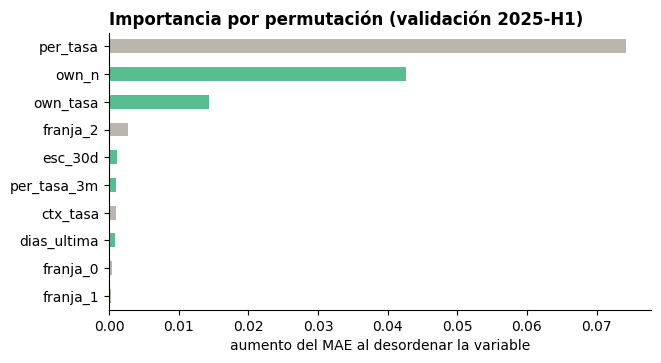

,MAE validación,diferencia
todas las variables,0.1465,0.0000
sin historial propio de la canción,0.1575,0.0110
"sin cansancio (días desde la última, escuchas 30 días)",0.1484,0.0019
sin tasa reciente de la persona (3 meses),0.1509,0.0044


In [7]:
vida_el = None if "ventana" in elegido else int(elegido.split("olvido ")[1].split(" ")[0])
perdida_el = elegido.split("· ")[-1]
X, y, Xv = DATOS_VAL[vida_el]
todas = list(X.columns)
GRUPOS = {"historial propio de la canción": [c for c in todas if c.startswith(("own_", "ownctx_"))],
          "cansancio (días desde la última, escuchas 30 días)": ["dias_ultima", "esc_30d"],
          "tasa reciente de la persona (3 meses)": ["per_tasa_3m"]}
def mae_cols(cols):
    m = HistGradientBoostingRegressor(**GB[perdida_el]).fit(X[cols], y)
    return mean_absolute_error(val["tasa_no_salto"], np.clip(m.predict(Xv[cols]), 0, 1))
ablacion = {"todas las variables": mae_cols(todas)}
for g, cs in GRUPOS.items():
    ablacion[f"sin {g}"] = mae_cols([c for c in todas if c not in cs])
ablacion = pd.Series(ablacion, name="MAE validación").to_frame()
ablacion["diferencia"] = ablacion["MAE validación"] - ablacion.loc["todas las variables", "MAE validación"]

m_val = HistGradientBoostingRegressor(**GB[perdida_el]).fit(X, y)
imp = permutation_importance(m_val, Xv, val["tasa_no_salto"], scoring="neg_mean_absolute_error", n_repeats=5, random_state=SEMILLA)
importancia = pd.Series(imp.importances_mean, index=Xv.columns).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 3.6))
importancia.head(10)[::-1].plot.barh(ax=ax, color=["#56BE91" if c.startswith(("own", "dias", "esc_30", "per_tasa_3m")) else GRIS for c in importancia.head(10).index[::-1]])
ax.set_title("Importancia por permutación (validación 2025-H1)"); ax.set_xlabel("aumento del MAE al desordenar la variable")
ruta_imp = guardar(fig, "07_importancia"); plt.show()
ablacion.round(4)

## 4. Modelo final y prueba única con el lote 2

Con lo elegido se entrena el modelo final con todos los cortes cuya etiqueta acaba antes del lote 2 (2022-07 … 2025-01) y se predice el lote 2 con escuchas anteriores al 1-7-2025. Se compara **en las mismas filas** con el modelo del notebook 05 y con la mediana por persona.

In [8]:
cortes_fin = cortes_hasta(CORTE)
X_fin, y_fin = apilar(cortes_fin, vida_el)
modelo_nuevo = HistGradientBoostingRegressor(**GB[perdida_el]).fit(X_fin, y_fin)

l2 = h[h["lote"] == 2]
te = recuentos(l2); te = te[te["n_escuchas"] >= MIN_ESCUCHAS].reset_index(drop=True)
te["tasa_no_salto"] = te["n_no_salto"] / te["n_escuchas"]
te["nuevo"] = np.clip(modelo_nuevo.predict(variables_t(te, CORTE, vida_el)), 0, 1)

m5, per5, src5 = modelo_05(CORTE)
t5 = tabla(l2, per5); t5 = t5[t5["n_escuchas"] >= MIN_ESCUCHAS].reset_index(drop=True)
t5["notebook_05"] = np.clip(m5.predict(matriz(t5, codificar(t5, src5))), 0, 1)
k = ["persona", "track_id", "franja", "tipo_dia"]
cmp = te[k + ["tasa_no_salto", "n_escuchas", "nuevo"]].merge(t5[k + ["notebook_05"]], on=k)
mediana = pd.concat([etiquetas(c, c + pd.DateOffset(months=6)) for c in cortes_fin[-2:]]).groupby("persona")["tasa_no_salto"].median()
cmp["mediana"] = cmp["persona"].map(mediana)
conocidas = set(zip(h[h["hora_local"] < CORTE]["persona"], h[h["hora_local"] < CORTE]["track_id"]))
cmp["conocida"] = [(p, t) in conocidas for p, t in zip(cmp["persona"], cmp["track_id"])]

MODELOS = ["notebook_05", "mediana", "nuevo"]
def resumen(d):
    return pd.Series({**{f"MAE_{m}": mean_absolute_error(d["tasa_no_salto"], d[m]) for m in MODELOS},
                      **{f"sesgo_{m}": (d[m] - d["tasa_no_salto"]).mean() for m in MODELOS},
                      "filas": len(d)})
lote2 = pd.DataFrame({"todas": resumen(cmp)})
for p, e in cmp.groupby("persona"): lote2[p] = resumen(e)
lote2["canciones nuevas"] = resumen(cmp[~cmp["conocida"]]); lote2["canciones conocidas"] = resumen(cmp[cmp["conocida"]])
sp = {m: spearman_intra(cmp["tasa_no_salto"], cmp[m], cmp["persona"]) for m in ["notebook_05", "nuevo"]}
print(f"Filas comunes: {len(cmp)} · Spearman dentro de cada persona: notebook 05 {sp['notebook_05']:.3f} · nuevo {sp['nuevo']:.3f}")

# Horizonte real del planteamiento: solo los 6 meses siguientes al corte
e6 = etiquetas(CORTE, CORTE + pd.DateOffset(months=6))
p6 = np.clip(modelo_nuevo.predict(variables_t(e6, CORTE, vida_el)), 0, 1)
horizonte6 = {"filas": len(e6), "MAE_nuevo": mean_absolute_error(e6["tasa_no_salto"], p6),
              "MAE_mediana": mean_absolute_error(e6["tasa_no_salto"], e6["persona"].map(mediana))}
print("Horizonte de 6 meses (jul-dic 2025):", {a: round(b, 4) for a, b in horizonte6.items()})
lote2.to_csv(SALIDA / "07_lote2_objetivo1.csv")
lote2.round(4)

Filas comunes: 8920 · Spearman dentro de cada persona: notebook 05 0.132 · nuevo 0.305
Horizonte de 6 meses (jul-dic 2025): {'filas': 2935, 'MAE_nuevo': 0.1623, 'MAE_mediana': 0.2113}


,todas,ander,daniel,canciones nuevas,canciones conocidas
MAE_notebook_05,0.1899,0.2266,0.0619,0.2220,0.1774
MAE_mediana,0.1882,0.2247,0.0610,0.2056,0.1814
MAE_nuevo,0.1596,0.1879,0.0611,0.1727,0.1546
sesgo_notebook_05,0.0398,0.0345,0.0583,-0.1094,0.0978
sesgo_mediana,0.0471,0.0431,0.0610,-0.0991,0.1039
sesgo_nuevo,0.0914,0.1003,0.0605,0.0949,0.0901
filas,8920.0000,6932.0000,1988.0000,2496.0000,6424.0000


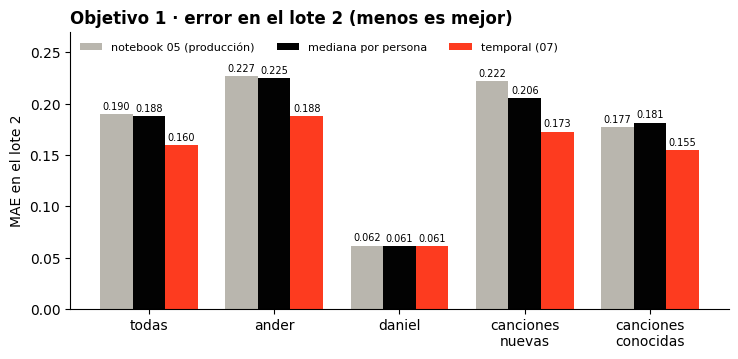

In [9]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
grupos = ["todas", "ander", "daniel", "canciones nuevas", "canciones conocidas"]
anchura = 0.26
nombres = {"notebook_05": "notebook 05 (producción)", "mediana": "mediana por persona", "nuevo": "temporal (07)"}
colores = {"notebook_05": GRIS, "mediana": NEGRO, "nuevo": "#FD3B1F"}
for i, m in enumerate(MODELOS):
    v = [lote2.loc[f"MAE_{m}", g] for g in grupos]
    b = ax.bar(np.arange(len(grupos)) + (i - 1) * anchura, v, anchura, label=nombres[m], color=colores[m])
    ax.bar_label(b, fmt="%.3f", fontsize=7, padding=2)
ax.set_xticks(np.arange(len(grupos)), [g.replace(" ", "\n") for g in grupos]); ax.set_ylabel("MAE en el lote 2")
ax.set_ylim(0, 0.27); ax.legend(frameon=False, fontsize=8, ncol=3, loc="upper left")
ax.set_title("Objetivo 1 · error en el lote 2 (menos es mejor)")
ruta_l2 = guardar(fig, "07_lote2_mae"); plt.show()

## 5. Objetivo 2 con el modelo nuevo

El recomendador sigue la regla del notebook 03/06: gusto de cada persona por canción y contexto → percentil dentro de la persona → **mínimo del grupo**, desempate por la media. Variantes que se prueban:

| Variante | Qué cambia |
| --- | --- |
| sistema 06 | El de producción: modelo del notebook 05; tasa real si hay 5+ escuchas, si no, la prevista |
| nuevo · regla real/prevista | Igual, pero la prevista sale del modelo temporal |
| nuevo · solo prevista | Usa siempre la prevista (también con 5+ escuchas) |
| nuevo · todo el historial | Candidatas de todo el historial (3+ escuchas), no solo de los últimos 18 meses |
| … + pop λ | Suma λ × percentil de popularidad reciente (escuchas del grupo en los últimos 6 meses) |

Se mide como en el notebook 06: en cada contexto se toman las 50 primeras canciones y, para cada miembro, la tasa de salto real **ponderada por escuchas** en el periodo siguiente, emparejada con el modelo base (las más escuchadas) y con intervalo bootstrap del 95 %. Negativo = la playlist se salta menos que la del modelo base.

**Elección en validación:** listas hechas con datos anteriores al 1-1-2025, evaluadas con enero-junio de 2025. Se elige la variante con la mayor reducción de saltos con la regla de 5+ escuchas cuyo intervalo no cruce el cero.

In [10]:
CONTEXTOS = [(f, td) for f in range(6) for td in ("laborable", "fin_semana")]
def ndcg(rel):
    rel = np.asarray(rel, float)
    if len(rel) == 0 or rel.max() == 0: return np.nan
    d = 1 / np.log2(np.arange(2, len(rel) + 2))
    return float((rel * d).sum() / (np.sort(rel)[::-1] * d).sum())

def candidatas(corte, todo_historial=False):
    p = h[h["hora_local"] < corte]
    if not todo_historial: p = p[p["hora_local"] >= corte - pd.DateOffset(months=18)]
    cat = p.groupby("track_id").agg(artista=("artista", "first"), album=("album", "first"), escuchas_grupo=("no_salto", "size")).reset_index()
    rec = h[(h["hora_local"] < corte) & (h["hora_local"] >= corte - pd.DateOffset(months=6))].groupby("track_id").size()
    cat["esc_6m"] = cat["track_id"].map(rec).fillna(0)
    if todo_historial: cat = cat[cat["escuchas_grupo"] >= 3]
    c = pd.concat([cat.assign(persona=pp, franja=f, tipo_dia=td) for pp in sorted(h["persona"].unique()) for f, td in CONTEXTOS],
                  ignore_index=True)
    return cat, c

def lista_grupo(corte, variante, lam, modelos):
    cat, c = candidatas(corte, variante == "nuevo · todo el historial")
    per18 = h[(h["hora_local"] >= corte - pd.DateOffset(months=18)) & (h["hora_local"] < corte)]
    r = recuentos(per18).set_index(k).reindex(pd.MultiIndex.from_frame(c[k])).fillna(0)
    real = np.where(r["n_escuchas"].to_numpy() >= MIN_ESCUCHAS, r["n_no_salto"].to_numpy() / np.maximum(r["n_escuchas"].to_numpy(), 1), np.nan)
    if variante == "sistema 06":
        m, per, src = modelos["05"]
        pt = per.groupby(["persona", "track_id"])["no_salto"].agg(["size", "sum"]); gt = pt.groupby("track_id").sum()
        own = pt.reindex(pd.MultiIndex.from_frame(c[["persona", "track_id"]])).fillna(0).to_numpy()
        tot = gt.reindex(c["track_id"]).fillna(0).to_numpy()
        n, ns = tot[:, 0] - own[:, 0], tot[:, 1] - own[:, 1]
        c["per_pct_shuffle"] = c["persona"].map(per.groupby("persona")["shuffle"].mean())
        c["grp_n_escuchas"] = n; c["grp_tasa_no_salto"] = np.where(n > 0, ns / np.maximum(n, 1), np.nan)
        prevista = np.clip(m.predict(matriz(c, codificar(c, src))), 0, 1)
    else:
        prevista = np.clip(modelos["nuevo"].predict(variables_t(c, corte, vida_el)), 0, 1)
    usa_real = variante in ("sistema 06", "nuevo · regla real/prevista")
    c["gusto"] = np.where(~np.isnan(real), real, prevista) if usa_real else prevista
    c["pct"] = c.groupby(["persona", "franja", "tipo_dia"])["gusto"].rank(pct=True)
    g = c.groupby(["track_id", "franja", "tipo_dia"]).agg(gusto_grupo=("pct", "min"), desempate=("pct", "mean"),
                                                          esc_6m=("esc_6m", "first")).reset_index()
    g["popularidad"] = g.groupby(["franja", "tipo_dia"])["esc_6m"].rank(pct=True)
    g["puntuacion"] = g["gusto_grupo"] + lam * g["popularidad"]
    return g.sort_values(["franja", "tipo_dia", "puntuacion", "desempate"], ascending=[True, True, False, False])

def lista_base(corte):
    cat, _ = candidatas(corte)
    return cat.merge(pd.DataFrame(CONTEXTOS, columns=["franja", "tipo_dia"]), how="cross").sort_values(
        ["franja", "tipo_dia", "escuchas_grupo"], ascending=[True, True, False])

def evaluar(lista, desde, hasta, umbral, n=50):
    r = recuentos(h[(h["hora_local"] >= desde) & (h["hora_local"] < hasta)]); r = r[r["n_escuchas"] >= umbral].copy()
    r["t"] = r["n_no_salto"] / r["n_escuchas"]
    out = {}
    for (f, td), l in lista.groupby(["franja", "tipo_dia"]):
        top = l.head(n).assign(pos=np.arange(min(n, len(l))))
        ev = top.merge(r[(r["franja"] == f) & (r["tipo_dia"] == td)], on=["track_id", "franja", "tipo_dia"])
        for p, e in ev.groupby("persona"):
            e = e.sort_values("pos")
            out[(f, td, p)] = (1 - np.average(e["t"], weights=e["n_escuchas"]), ndcg(e["t"]), len(e))
    return pd.DataFrame(out, index=["tasa_salto", "ndcg", "evaluables"]).T

def comparar(corte, hasta, variantes, modelos, n=50):
    filas = []
    base = {u: evaluar(lista_base(corte), corte, hasta, u, n) for u in (MIN_ESCUCHAS, 1)}
    for nombre, (variante, lam) in variantes.items():
        L = lista_grupo(corte, variante, lam, modelos)
        for u in (MIN_ESCUCHAS, 1):
            s = evaluar(L, corte, hasta, u, n)
            par = pd.concat([s["tasa_salto"], base[u]["tasa_salto"]], axis=1, keys=["s", "b"]).dropna()
            dif = (par["s"] - par["b"]).to_numpy()
            rng = np.random.default_rng(SEMILLA); boot = [rng.choice(dif, len(dif)).mean() for _ in range(2000)]
            filas.append({"variante": nombre, "evaluacion": "5+ escuchas" if u > 1 else "todas las escuchas",
                          "diferencia_puntos": dif.mean() * 100, "ic95_inf": np.percentile(boot, 2.5) * 100,
                          "ic95_sup": np.percentile(boot, 97.5) * 100, "pares": len(dif),
                          "ndcg_sistema": s["ndcg"].mean(), "ndcg_base": base[u]["ndcg"].mean(),
                          "evaluables_sistema": s["evaluables"].mean(), "evaluables_base": base[u]["evaluables"].mean()})
    return pd.DataFrame(filas).set_index(["variante", "evaluacion"])

In [11]:
VARIANTES = {"sistema 06": ("sistema 06", 0.0),
             "nuevo · regla real/prevista": ("nuevo · regla real/prevista", 0.0),
             "nuevo · solo prevista": ("nuevo · solo prevista", 0.0),
             "nuevo · todo el historial": ("nuevo · todo el historial", 0.0),
             "nuevo · solo prevista + pop 0,1": ("nuevo · solo prevista", 0.1),
             "nuevo · regla + pop 0,1": ("nuevo · regla real/prevista", 0.1),
             "nuevo · regla + pop 0,25": ("nuevo · regla real/prevista", 0.25)}
modelos_val = {"05": modelo_05(INICIO_VAL),
               "nuevo": HistGradientBoostingRegressor(**GB[perdida_el]).fit(*apilar(cortes_val, vida_el))}
obj2_val = comparar(INICIO_VAL, FIN_VAL, VARIANTES, modelos_val)
obj2_val.to_csv(SALIDA / "07_objetivo2_validacion.csv")
cinco = obj2_val.xs("5+ escuchas", level="evaluacion")
validas = cinco[(cinco["ic95_sup"] < 0) & (cinco["pares"] >= 10)]
variante_el = validas["diferencia_puntos"].idxmin() if len(validas) else "sistema 06"
print("Variante elegida en validación:", variante_el)
obj2_val.round(3)

Variante elegida en validación: sistema 06


diferencia_puntos  \
variante                        evaluacion                              
sistema 06                      5+ escuchas                    -8.982   
                                todas las escuchas             -5.566   
nuevo · regla real/prevista     5+ escuchas                    -5.032   
                                todas las escuchas             -5.615   
nuevo · solo prevista           5+ escuchas                     8.824   
                                todas las escuchas             -4.598   
nuevo · todo el historial       5+ escuchas                     8.824   
                                todas las escuchas             -4.152   
nuevo · solo prevista + pop 0,1 5+ escuchas                     8.824   
                                todas las escuchas             -4.357   
nuevo · regla + pop 0,1         5+ escuchas                    -4.623   
                                todas las escuchas             -4.621   
nuevo · regla + pop 0,25        5+ escuchas                    -5.215   
                                todas las escuchas             -5.635   

                                                    ic95_inf  ic95_sup  pares  \
variante                        evaluacion                                      
sistema 06                      5+ escuchas          -16.115    -1.389     11   
                                todas las escuchas   -10.967     0.964     21   
nuevo · regla real/prevista     5+ escuchas          -11.327     1.333      7   
                                todas las escuchas   -11.392     1.053     22   
nuevo · solo prevista           5+ escuchas            8.824     8.824      1   
                                todas las escuchas   -16.019     7.776     17   
nuevo · todo el historial       5+ escuchas            8.824     8.824      1   
                                todas las escuchas   -15.586     7.917     17   
nuevo · solo prevista + pop 0,1 5+ escuchas            8.824     8.824      1   
                                todas las escuchas   -15.739     7.792     17   
nuevo · regla + pop 0,1         5+ escuchas          -11.327     2.340      7   
                                todas las escuchas    -9.704     1.498     22   
nuevo · regla + pop 0,25        5+ escuchas          -12.771     2.320      7   
                                todas las escuchas   -11.114     0.844     22   

                                                    ndcg_sistema  ndcg_base  \
variante                        evaluacion                                    
sistema 06                      5+ escuchas                0.953      0.919   
                                todas las escuchas         0.905      0.877   
nuevo · regla real/prevista     5+ escuchas                0.996      0.919   
                                todas las escuchas         0.936      0.877   
nuevo · solo prevista           5+ escuchas                0.996      0.919   
                                todas las escuchas         0.988      0.877   
nuevo · todo el historial       5+ escuchas                0.996      0.919   
                                todas las escuchas         0.988      0.877   
nuevo · solo prevista + pop 0,1 5+ escuchas                0.996      0.919   
                                todas las escuchas         0.995      0.877   
nuevo · regla + pop 0,1         5+ escuchas                0.977      0.919   
                                todas las escuchas         0.940      0.877   
nuevo · regla + pop 0,25        5+ escuchas                0.974      0.919   
                                todas las escuchas         0.926      0.877   

                                                    evaluables_sistema  \
variante                        evaluacion                               
sistema 06                      5+ escuchas                      5.462   
                                todas las escuchas              18.905   
nuevo · regla real/previs

*Las variantes «solo prevista» y «todo el historial» dejan muy pocas canciones evaluables (la lista se llena de canciones que casi no se escuchan después), así que su diferencia se basa en muy pocos pares y no es fiable; por eso la regla exige al menos 10 pares.*

### 5.1 Prueba única con el lote 2

In [12]:
FIN_DATOS = h["hora_local"].max() + pd.Timedelta(seconds=1)
modelos_l2 = {"05": modelo_05(CORTE), "nuevo": modelo_nuevo}
obj2_l2 = comparar(CORTE, FIN_DATOS, {"sistema 06": VARIANTES["sistema 06"], variante_el: VARIANTES[variante_el]}, modelos_l2)
obj2_l2.to_csv(SALIDA / "07_objetivo2_lote2.csv")
obj2_l2.round(3)

diferencia_puntos  ic95_inf  ic95_sup  pares  \
variante   evaluacion                                                         
sistema 06 5+ escuchas                    -5.444   -11.016     0.193     15   
           todas las escuchas             -2.411    -6.664     1.961     22   

                               ndcg_sistema  ndcg_base  evaluables_sistema  \
variante   evaluacion                                                        
sistema 06 5+ escuchas                0.923      0.890              10.882   
           todas las escuchas         0.891      0.903              22.696   

                               evaluables_base  
variante   evaluacion                           
sistema 06 5+ escuchas                  20.875  
           todas las escuchas           27.696

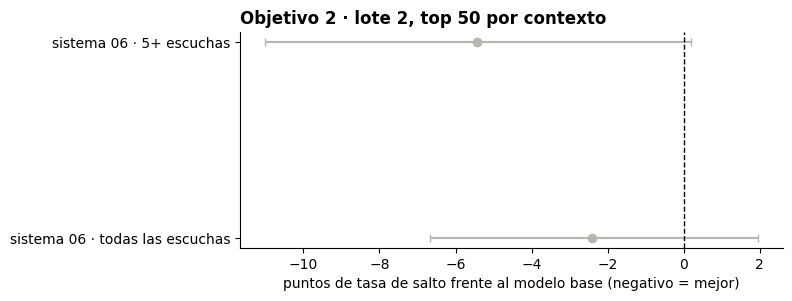

In [13]:
fig, ax = plt.subplots(figsize=(7, 2.8))
d = obj2_l2.reset_index(); d["etiqueta"] = d["variante"] + " · " + d["evaluacion"]
ys = np.arange(len(d))[::-1]
for i, (_, r) in zip(ys, d.iterrows()):
    color = GRIS if r["variante"] == "sistema 06" else "#FD3B1F"
    ax.errorbar(r["diferencia_puntos"], i, xerr=[[r["diferencia_puntos"] - r["ic95_inf"]], [r["ic95_sup"] - r["diferencia_puntos"]]],
                fmt="o", color=color, ecolor=color, capsize=3)
ax.axvline(0, color=NEGRO, lw=1, ls="--"); ax.set_yticks(ys, d["etiqueta"])
ax.set_xlabel("puntos de tasa de salto frente al modelo base (negativo = mejor)")
ax.set_title("Objetivo 2 · lote 2, top 50 por contexto")
ruta_o2 = guardar(fig, "07_objetivo2_lote2"); plt.show()

## 6. Registro en MLflow y resultados guardados

Se registran las ejecuciones en el experimento `mejoras_temporal` y se guarda el modelo temporal en `modelos/07_modelo_temporal.joblib` (con la lista de columnas), para que la API pueda usarlo si el equipo decide cambiar de modelo. El alias `produccion` del registro **no se cambia** en este notebook: es una decisión del equipo.

In [14]:
registrar("validacion temporal", {"cortes": ",".join(f"{c:%Y-%m}" for c in cortes_val), "validacion": "2025-01..2025-06",
                                  "elegido": elegido},
          {f"val_mae_{i}": v for i, v in enumerate(validacion["MAE"])} | {"val_mae_elegido": validacion.loc[elegido, "MAE"]},
          [ruta_imp])
registrar("modelo temporal · lote 2", {"perdida": perdida_el, "ventana": "18 meses" if vida_el is None else f"olvido {vida_el} dias",
                                       "cortes": ",".join(f"{c:%Y-%m}" for c in cortes_fin), "variables": len(X_fin.columns),
                                       "filas_entrenamiento": len(X_fin)},
          {"lote2_mae": lote2.loc["MAE_nuevo", "todas"], "lote2_mae_notebook05": lote2.loc["MAE_notebook_05", "todas"],
           "lote2_mae_mediana": lote2.loc["MAE_mediana", "todas"], "lote2_sesgo": lote2.loc["sesgo_nuevo", "todas"],
           "lote2_spearman_intra": sp["nuevo"], "lote2_spearman_intra_notebook05": sp["notebook_05"],
           "horizonte6_mae": horizonte6["MAE_nuevo"]}, [ruta_l2])
o = obj2_l2.reset_index()
registrar("objetivo 2 · lote 2", {"variante": variante_el, "N": 50},
          {f"{'sist06' if r.variante == 'sistema 06' else 'nuevo'}_{'5' if r.evaluacion.startswith('5') else 'todas'}_dif_puntos": r.diferencia_puntos
           for r in o.itertuples()}, [ruta_o2])

(RAIZ / "modelos").mkdir(exist_ok=True)
joblib.dump({"modelo": modelo_nuevo, "columnas": list(X_fin.columns), "vida": vida_el, "perdida": perdida_el,
             "cortes": [str(c) for c in cortes_fin]}, RAIZ / "modelos" / "07_modelo_temporal.joblib")
json.dump({"elegido_objetivo1": elegido, "validacion": validacion.round(4).reset_index().to_dict("records"),
           "ablacion": ablacion["MAE validación"].round(4).to_dict(),
           "lote2": lote2.round(4).to_dict(), "spearman_lote2": sp, "horizonte6": horizonte6,
           "variante_objetivo2": variante_el, "objetivo2_lote2": obj2_l2.round(3).reset_index().to_dict("records")},
          open(SALIDA / "07_resumen.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1, default=float)
print("Guardado:", SALIDA / "07_resumen.json")

Guardado: /content/drive/MyDrive/proyecto-Ebaluacion1/data/salida/07_resumen.json


## 7. Conclusiones

**Objetivo 1: mejora clara.** Lo que más aporta es cambiar el planteamiento a previsión: las variables salen del pasado y lo que se predice es la tasa de los 6 meses siguientes.

| Lote 2 (8.920 filas comunes) | Notebook 05 (producción) | Mediana por persona | **Temporal (07)** |
| --- | --- | --- | --- |
| MAE | 0,190 | 0,188 | **0,160** (−16 %) |
| Spearman dentro de cada persona | 0,132 | — | **0,305** |
| MAE Ander / Daniel | 0,227 / 0,062 | 0,225 / 0,061 | **0,188** / 0,061 |
| MAE canciones nuevas / conocidas | 0,222 / 0,177 | 0,206 / 0,181 | **0,173 / 0,155** |

- Es la primera vez que el modelo **gana claramente a la mediana** de cada persona. En el horizonte para el que está pensado (6 meses: julio a diciembre de 2025) el MAE es 0,162, frente a 0,211 de la mediana.
- La elección se hizo solo con la validación de 2025-H1. Ganó el **olvido gradual de 730 días con pérdida absoluta** (MAE 0,147), casi empatado con la ventana de 18 meses (0,148). Ambos quedan muy por delante del enfoque 05 (0,206) y de la mediana (0,195). En una ejecución local con otra versión de scikit-learn ganaba la ventana de 18 meses por una diferencia igual de pequeña. Es decir, las dos opciones son equivalentes y la diferencia no es significativa.
- La ablación confirma que los tres grupos nuevos aportan. Quitar el historial propio de la canción sube el MAE en +0,011; quitar la tasa de los últimos 3 meses, +0,004; quitar el cansancio, +0,002.
- La mejora es toda de Ander. En Daniel nada gana a la mediana porque casi nunca salta (tasa 0,92).
- **Aviso:** el modelo nuevo sobrestima la tasa en el lote 2 (sesgo +0,09, frente a +0,04 del 05). La razón es que Ander salta cada vez más (0,55 → 0,44, notebook 04) y el modelo aprende de su pasado. Ordena mejor y falla menos, pero sigue haciendo falta la vigilancia mensual de la calibración del notebook 04.

**Objetivo 2: se mantiene el sistema 06.** En la validación, el recomendador con el modelo nuevo deja muy pocas canciones evaluables con la regla de 5 o más escuchas (7 pares de contexto × miembro o menos). Por eso ninguna variante nueva cumple la regla de elección. La que la cumple es el sistema actual: −9,0 puntos de saltos frente a «las más escuchadas», IC −16,1 a −1,4. Ni la popularidad reciente ni las candidatas de todo el historial mejoran. En el lote 2, el sistema 06 se salta 5,4 puntos menos que el modelo base (IC −11,0 a +0,2) y 2,4 menos con todas las escuchas, en la línea del notebook 06.

**Decisión propuesta:**
- Objetivo 1: usar el modelo temporal.
- Objetivo 2: seguir ordenando con el modelo del notebook 05 y la regla real/prevista.

El alias `produccion` del registro no se ha cambiado en este notebook. Si el equipo lo aprueba, hay que adaptar `api/preparar_datos.py` y `api/caracteristicas.py` al planteamiento temporal para la predicción del objetivo 1, y actualizar el informe (modelos finales y conclusiones).

**Transparencia:** todas las decisiones se tomaron con la validación de 2025-H1. El lote 2 se evaluó una vez con lo ya elegido y no se ha ajustado nada después.

## 8. Recomendador con todo el historial y reparto mínimo

La API tiene, además del recomendador de siempre (últimos 18 meses), la opción `"historial": "completo"` (`api/servicio.py`). Esta sección la evalúa con la misma comparación emparejada que la sección 5 y explica por qué hace falta el **reparto mínimo**.

| Variante | Candidatas | Gusto de cada miembro | Orden |
| --- | --- | --- | --- |
| sistema 06 (producción) | Canciones del grupo en los últimos 18 meses | Tasa real si hay 5+ escuchas en el contexto; si no, la prevista | Mínimo de percentiles, desempate por la media |
| completo sin reparto | Canciones con 3 o más escuchas del grupo en **todo** el historial | Suavizado: (no saltos + 5 × prevista) / (escuchas + 5), con las escuchas de toda la vida en ese contexto | Igual |
| **completo con reparto** (la de la API) | Igual | Igual | Igual y, además, cada miembro conoce al menos **1/3** de cualquier tramo inicial de la lista |

La predicción es la del modelo de producción (notebook 05), como en la API. «Conocer» una canción = haberla escuchado alguna vez antes del corte.

**Validación de tres semestres** (más pares que con uno solo): listas hechas con datos anteriores al 1-1-2024, al 1-7-2024 y al 1-1-2025, evaluadas cada una con los 6 meses siguientes. Las diferencias de todos los contextos, miembros y semestres se juntan para el intervalo bootstrap. El lote 2 se usa una sola vez al final.

In [ ]:
MIN_CANDIDATA, K_SUAVE, FRACCION_REPARTO, N_LISTA = 3, 5, 1 / 3, 50     # los mismos valores que api/servicio.py

def prevista_05(c, modelos):
    """Tasa prevista por el modelo del notebook 05 para las filas c (como el «sistema 06» de la sección 5)."""
    m, per, src = modelos["05"]
    pt = per.groupby(["persona", "track_id"])["no_salto"].agg(["size", "sum"]); gt = pt.groupby("track_id").sum()
    own = pt.reindex(pd.MultiIndex.from_frame(c[["persona", "track_id"]])).fillna(0).to_numpy()
    tot = gt.reindex(c["track_id"]).fillna(0).to_numpy()
    n, ns = tot[:, 0] - own[:, 0], tot[:, 1] - own[:, 1]
    c = c.assign(per_pct_shuffle=c["persona"].map(per.groupby("persona")["shuffle"].mean()),
                 grp_n_escuchas=n, grp_tasa_no_salto=np.where(n > 0, ns / np.maximum(n, 1), np.nan))
    return np.clip(m.predict(matriz(c, codificar(c, src))), 0, 1)

def reparto(orden, sabe, limite, fraccion=FRACCION_REPARTO):
    """Copia de Servicio._reparto (api/servicio.py): reordena la lista para que, en cualquier tramo inicial de
    longitud L, cada miembro conozca al menos floor(fraccion × L) canciones, si le quedan canciones conocidas."""
    limite = min(limite, len(orden))
    conocidas = {p: [t for t in orden if t in sabe[p]] for p in sabe}
    puntero, cuenta = {p: 0 for p in sabe}, {p: 0 for p in sabe}
    usadas, final, i = set(), [], 0
    while len(final) < limite:
        elegida = None
        for p in conocidas:
            if cuenta[p] < int(fraccion * (len(final) + 1)):
                while puntero[p] < len(conocidas[p]) and conocidas[p][puntero[p]] in usadas:
                    puntero[p] += 1
                if puntero[p] < len(conocidas[p]):
                    elegida = conocidas[p][puntero[p]]; break
        if elegida is None:
            while orden[i] in usadas:
                i += 1
            elegida = orden[i]
        usadas.add(elegida); final.append(elegida)
        for p in conocidas:
            cuenta[p] += elegida in sabe[p]
    return final

def lista_completo(corte, modelos, con_reparto=True, n=N_LISTA):
    """Variante «completo» de la API para todos los contextos, ordenada dentro de cada contexto."""
    _, c = candidatas(corte, todo_historial=True)                     # 3+ escuchas del grupo antes del corte
    antes = h[h["hora_local"] < corte]
    r = recuentos(antes).set_index(k).reindex(pd.MultiIndex.from_frame(c[k])).fillna(0)
    c["gusto"] = (r["n_no_salto"].to_numpy() + K_SUAVE * prevista_05(c, modelos)) / (r["n_escuchas"].to_numpy() + K_SUAVE)
    c["pct"] = c.groupby(["persona", "franja", "tipo_dia"])["gusto"].rank(pct=True)
    g = (c.groupby(["track_id", "franja", "tipo_dia"]).agg(gusto_grupo=("pct", "min"), desempate=("pct", "mean"))
          .reset_index().sort_values(["franja", "tipo_dia", "gusto_grupo", "desempate"], ascending=[True, True, False, False]))
    if not con_reparto:
        return g
    sabe = {p: set(d["track_id"]) for p, d in antes.groupby("persona")}
    partes = []
    for (f, td), l in g.groupby(["franja", "tipo_dia"], sort=False):
        orden = reparto(list(l["track_id"]), sabe, n)
        partes.append(l.set_index("track_id").loc[orden].reset_index())
    return pd.concat(partes, ignore_index=True)

VARIANTES_8 = ["sistema 06", "completo sin reparto", "completo con reparto"]
def listas_8(corte, modelos):
    return {"sistema 06": lista_grupo(corte, "sistema 06", 0.0, modelos),
            "completo sin reparto": lista_completo(corte, modelos, con_reparto=False),
            "completo con reparto": lista_completo(corte, modelos, con_reparto=True)}

def diferencias(listas, corte, hasta, n=N_LISTA):
    """Diferencia de tasa de salto (sistema − base) por contexto y miembro, con 5+ escuchas y con todas."""
    filas = []
    for u in (MIN_ESCUCHAS, 1):
        base = evaluar(lista_base(corte), corte, hasta, u, n)
        for nombre, L in listas.items():
            s = evaluar(L, corte, hasta, u, n)
            par = pd.concat([s["tasa_salto"], base["tasa_salto"]], axis=1, keys=["s", "b"]).dropna()
            filas += [{"variante": nombre, "evaluacion": "5+ escuchas" if u > 1 else "todas las escuchas",
                       "corte": f"{corte:%Y-%m}", "dif": d, "evaluables": s["evaluables"].mean(),
                       "ndcg": s["ndcg"].mean()} for d in (par["s"] - par["b"]).to_numpy()]
    return pd.DataFrame(filas)

def resumir(dif):
    def una(d):
        rng = np.random.default_rng(SEMILLA); x = d["dif"].to_numpy()
        boot = [rng.choice(x, len(x)).mean() for _ in range(2000)]
        return pd.Series({"diferencia_puntos": x.mean() * 100, "ic95_inf": np.percentile(boot, 2.5) * 100,
                          "ic95_sup": np.percentile(boot, 97.5) * 100, "pares": len(x),
                          "evaluables_por_contexto": d["evaluables"].mean()})
    return dif.groupby(["variante", "evaluacion"], sort=False).apply(una)


### 8.1 Validación de tres semestres

In [ ]:
CORTES_8 = [pd.Timestamp(f, tz=ZONA) for f in ("2024-01-01", "2024-07-01", "2025-01-01")]
dif_val, listas_val = [], {}
for c in CORTES_8:
    listas_val[c] = listas_8(c, {"05": modelo_05(c)})
    dif_val.append(diferencias(listas_val[c], c, c + pd.DateOffset(months=6)))
dif_val = pd.concat(dif_val, ignore_index=True)
obj2_val_8 = resumir(dif_val)
obj2_val_8.to_csv(SALIDA / "07_historial_completo_validacion.csv")
obj2_val_8.round(2)

### 8.2 Qué canciones entran en la lista

La evaluación solo puede medir canciones que cada miembro **volvió a escuchar** en el periodo siguiente, así que no ve si la lista es de una sola persona. Por eso se mira también su composición: de las 50 primeras canciones de cada contexto, qué parte conoce cada miembro y qué parte son **antiguas** (no sonaron en los 18 meses anteriores al corte, así que el sistema 06 no podría elegirlas).

In [ ]:
def composicion(listas, corte, n=N_LISTA):
    antes = h[h["hora_local"] < corte]
    sabe = {p: set(d["track_id"]) for p, d in antes.groupby("persona")}
    ult18 = set(antes[antes["hora_local"] >= corte - pd.DateOffset(months=18)]["track_id"])
    personas = sorted(sabe)
    filas = {}
    for nombre, L in listas.items():
        top = L.groupby(["franja", "tipo_dia"], sort=False).head(n)
        t = top["track_id"]
        quien = pd.DataFrame({p: t.isin(sabe[p]).to_numpy() for p in personas})
        fila = {f"conoce {p} (%)": quien[p].mean() * 100 for p in personas}
        fila["conocen todos (%)"] = quien.all(axis=1).mean() * 100
        for p in personas:
            fila[f"solo {p} (%)"] = (quien[p] & (quien.sum(axis=1) == 1)).mean() * 100
        fila["antiguas (%)"] = (~t.isin(ult18)).mean() * 100
        filas[nombre] = fila
    return pd.DataFrame(filas).T

comp_val = pd.concat({f"{c:%Y-%m}": composicion(listas_val[c], c) for c in CORTES_8}).groupby(level=1, sort=False).mean()
comp_val.round(1)

### 8.3 Prueba única con el lote 2

In [ ]:
listas_l2 = listas_8(CORTE, {"05": modelos_l2["05"]})
dif_l2 = diferencias(listas_l2, CORTE, FIN_DATOS)
obj2_l2_8 = resumir(dif_l2)
obj2_l2_8.to_csv(SALIDA / "07_historial_completo_lote2.csv")
comp_l2 = composicion(listas_l2, CORTE)
comp_l2.to_csv(SALIDA / "07_historial_completo_composicion.csv")
display(obj2_l2_8.round(2))
comp_l2.round(1)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for ax, (titulo, tabla_r) in zip(axes, [("Validación (3 semestres)", obj2_val_8), ("Lote 2", obj2_l2_8)]):
    d = tabla_r.reset_index()
    ys = np.arange(len(d))[::-1]
    for y_, (_, r) in zip(ys, d.iterrows()):
        col = COLOR["ander"] if r["ic95_sup"] < 0 else (COLOR["daniel"] if r["ic95_inf"] > 0 else GRIS)
        ax.plot([r["ic95_inf"], r["ic95_sup"]], [y_, y_], color=col, lw=2)
        ax.plot(r["diferencia_puntos"], y_, "o", color=NEGRO if r["variante"] == "completo con reparto" else col)
    ax.axvline(0, color=NEGRO, lw=0.8)
    ax.set_yticks(ys, d["variante"] + " · " + d["evaluacion"])
    ax.set_title(titulo); ax.set_xlabel("puntos de tasa de salto frente a «las más escuchadas»")
fig.suptitle("Recomendador con todo el historial: diferencia de saltos e IC 95 % (negativo = mejor)", x=0.01, y=1.06, ha="left",
             fontweight="bold")
guardar(fig, "07_historial_completo"); plt.show()

# Registro en MLflow, en el mismo experimento que el resto del notebook
for etiqueta, tabla_r, comp in [("validacion 3 semestres", obj2_val_8, comp_val), ("lote 2", obj2_l2_8, comp_l2)]:
    for (variante, evaluacion), r in tabla_r.iterrows():
        nombre = f"historial completo · {variante} · {etiqueta} · {evaluacion}"
        metricas = {"diferencia_puntos": r["diferencia_puntos"], "ic95_inf": r["ic95_inf"], "ic95_sup": r["ic95_sup"],
                    "pares": r["pares"]}
        metricas.update({c.replace(" (%)", "").replace(" ", "_"): v for c, v in comp.loc[variante].items()})
        registrar(nombre, {"variante": variante, "periodo": etiqueta, "evaluacion": evaluacion, "n": N_LISTA,
                           "min_candidata": MIN_CANDIDATA, "k_suavizado": K_SUAVE, "reparto": FRACCION_REPARTO}, metricas)

v5, vt = obj2_val_8.xs("5+ escuchas", level="evaluacion"), obj2_val_8.xs("todas las escuchas", level="evaluacion")
l5, lt = obj2_l2_8.xs("5+ escuchas", level="evaluacion"), obj2_l2_8.xs("todas las escuchas", level="evaluacion")
sin = comp_val.loc["completo sin reparto"]; con = comp_val.loc["completo con reparto"]
solo_max = max((c for c in sin.index if c.startswith("solo ")), key=lambda c: sin[c])
print(f"Validación · 5+ escuchas: sistema 06 {v5.loc['sistema 06', 'diferencia_puntos']:+.1f} · "
      f"completo con reparto {v5.loc['completo con reparto', 'diferencia_puntos']:+.1f} puntos")
print(f"Validación · todas: sistema 06 {vt.loc['sistema 06', 'diferencia_puntos']:+.1f} · "
      f"completo con reparto {vt.loc['completo con reparto', 'diferencia_puntos']:+.1f} puntos")
print(f"Lote 2 · 5+ escuchas: sistema 06 {l5.loc['sistema 06', 'diferencia_puntos']:+.1f} · "
      f"completo con reparto {l5.loc['completo con reparto', 'diferencia_puntos']:+.1f} puntos")
print(f"Lote 2 · todas: sistema 06 {lt.loc['sistema 06', 'diferencia_puntos']:+.1f} · "
      f"completo con reparto {lt.loc['completo con reparto', 'diferencia_puntos']:+.1f} puntos")
print(f"Sin reparto, el {sin[solo_max]:.0f} % de la lista es de canciones que conoce {solo_max[5:-4]} y nadie más; "
      f"con reparto, el {con[solo_max]:.0f} %. Antiguas con reparto: {con['antiguas (%)']:.0f} %.")

### 8.4 Conclusiones de la sección 8

- **Sin reparto, la lista deja de ser del grupo.** Con todo el historial, la variante sin reparto se llena de canciones que conoce un solo miembro (la tabla de composición de 8.2), y la evaluación con el historial no lo ve, porque solo mide canciones que cada miembro volvió a escuchar. El reparto mínimo (cada miembro conoce al menos un tercio de cualquier tramo inicial) lo corrige sin cambiar la regla del mínimo.
- **Qué dicen las cifras.** Las diferencias de las celdas anteriores comparan cada variante con «las más escuchadas» en los mismos contextos y miembros. Una variante solo se considera mejor si su intervalo no cruza el cero; con dos personas hay pocos pares, sobre todo con la regla de 5+ escuchas.
- **Decisión:** el recomendador por defecto sigue siendo el de 18 meses (sistema 06, el evaluado en el notebook 06), y «todo el historial» queda como **opción** en la API y el panel (`"historial": "completo"`), con el reparto mínimo.
- **Límite de la evaluación:** con el historial no se puede saber si al grupo le gustaría volver a oír una canción olvidada, porque nadie la ha vuelto a poner. Para eso haría falta una prueba real: escuchar a ciegas en un viaje la playlist de cada opción y contar los saltos.

## 9. Versiones de las librerías

Para que Colab y local den las mismas cifras (apartado A.6 del informe), esta celda escribe las versiones exactas con las que se ha ejecutado el notebook en `requirements-ia.txt` (en la raíz del proyecto; en Colab, en la carpeta de Drive). Ese fichero es el que se sube al repositorio.

In [ ]:
from importlib.metadata import version, PackageNotFoundError
PAQUETES = ["pandas", "numpy", "scipy", "scikit-learn", "matplotlib", "mlflow", "joblib"]
lineas = []
for p in PAQUETES:
    try:
        lineas.append(f"{p}=={version(p)}")
    except PackageNotFoundError:
        lineas.append(f"# {p}: no instalado en este entorno")
import platform
cabecera = [f"# Versiones con las que se ejecutó notebooks/07_mejoras_temporal.ipynb ({'Google Colab' if EN_COLAB else 'local'}, "
            f"Python {platform.python_version()}, {pd.Timestamp.now(tz=ZONA):%Y-%m-%d})",
            "# Instalar con: pip install -r requirements-ia.txt"]
(RAIZ / "requirements-ia.txt").write_text("\n".join(cabecera + lineas) + "\n", encoding="utf-8")
print("\n".join(cabecera + lineas))